# Exercise 3

In [2]:
# random search function
def random_search(g,alpha_choice,max_its,w,num_samples):
    # run random search
    weight_history = []         # container for w history
    cost_history = []           # container for corresponding cost function history
    alpha = 0
    for k in range(1,max_its+1):
        # check if diminishing steplength rule used
        if alpha_choice == 'diminishing':
            alpha = 1/float(k)
        else:
            alpha = alpha_choice
            
        # record weights and cost evaluation
        weight_history.append(w)
        cost_history.append(g(w))
        
        # construct set of random unit directions
        directions = np.random.randn(num_samples,np.size(w))
        norms = np.sqrt(np.sum(directions*directions,axis = 1))[:,np.newaxis]
        directions = directions/norms   
        
        ### pick best descent direction
        # compute all new candidate points
        w_candidates = w + alpha*directions
        
        # evaluate all candidates
        evals = np.array([g(w_val) for w_val in w_candidates])

        # if we find a real descent direction take the step in its direction
        ind = np.argmin(evals)
        if g(w_candidates[ind]) < g(w):
            # pluck out best descent direction
            d = directions[ind,:]
        
            # take step
            w = w + alpha*d
        
    # record weights and cost evaluation
    weight_history.append(w)
    cost_history.append(g(w))
    return weight_history,cost_history

In [3]:
import numpy as np
# defining g 
g = lambda w: np.dot(w.T,w) + 2
# parametric settings
alpha_choice = 1; w = np.array([3,4]); num_samples = 1000; max_its = 5
# running random search
weight_history, cost_history = random_search(g,alpha_choice,max_its,w,num_samples)

3.1-

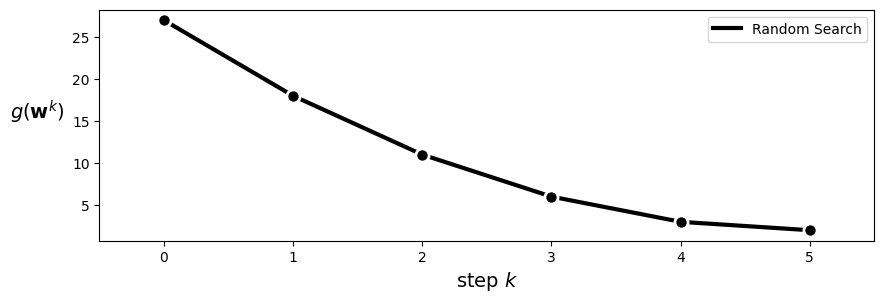

In [4]:
from MLRPlotting import static_plotter

# import custom plotting tools
static_plotter = static_plotter.Visualizer()

# plot the cost function history
static_plotter.plot_cost_histories([cost_history],start=0,points=True,labels=[r'Random Search'])

3.2-

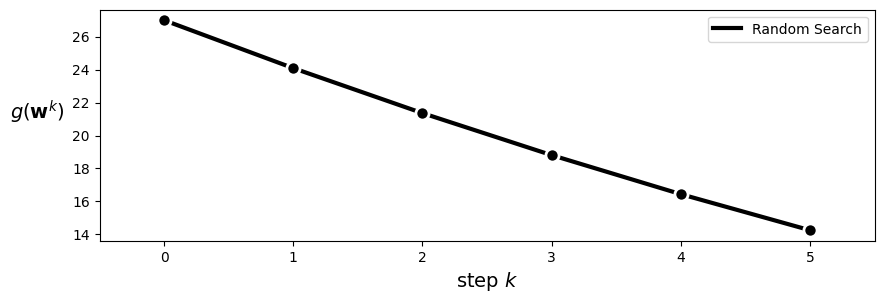

In [5]:
# modified parametric settings
alpha_choice = 0.3; w = np.array([3,4]); num_samples = 1000; max_its = 5
# running random search
weight_history, cost_history = random_search(g,alpha_choice,max_its,w,num_samples)

# plotting the cost histories
from MLRPlotting import static_plotter

# import custom plotting tools
static_plotter = static_plotter.Visualizer()

# plot the cost function history
static_plotter.plot_cost_histories([cost_history],start=0,points=True,labels=[r'Random Search'])

The result is worser than the previous one. The minim found is around 14 while the one in the first exemple was less than 5.

3.3-

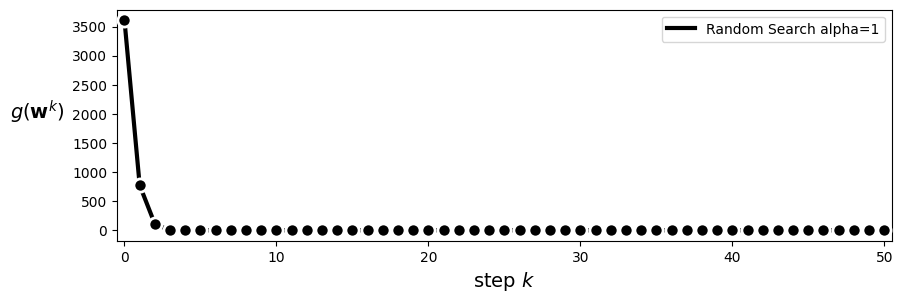

In [25]:
# defining g
def g(w): 
    return 100 * (w[1] - w[0]**2)**2 + (w[0] - 1)**2

# first run with alpha = 1
alpha_choice = 1; w = np.array([-2,-2]); num_samples = 1000; max_its = 50
weight_history_1, cost_history_1 = random_search(g,alpha_choice,max_its,w,num_samples)

# plot the cost function history
static_plotter.plot_cost_histories([cost_history_1],start=0,points=True,labels=[r'Random Search alpha=1'])

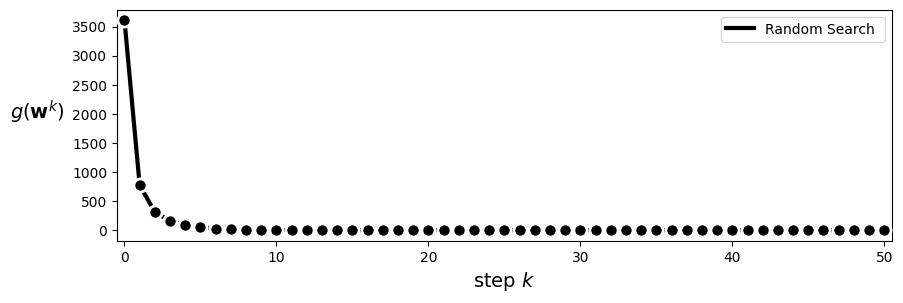

In [26]:
# first run with alpha = 1/k
alpha_choice = "diminishing"
weight_history_2, cost_history_2 = random_search(g,alpha_choice,max_its,w,num_samples)

# plot the cost function history
static_plotter.plot_cost_histories([cost_history_2],start=0,points=True,labels=[r'Random Search '])

The first plot drop a little bit faster at the beginning and both plots has the same allure afterward.

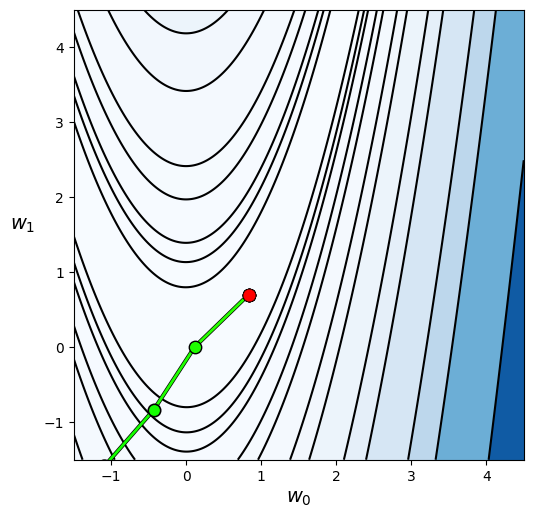

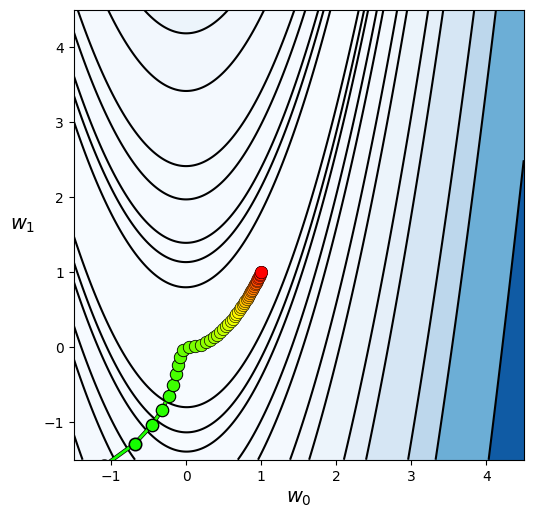

In [ ]:
# contour plot of the function g with overlayed w_history
static_plotter.two_input_contour_plot(g,weight_history_1,xmin = -1.5,xmax = 4.5,ymin = -1.5,ymax = 4.5,num_contours = 30,show_original = False)
static_plotter.two_input_contour_plot(g,weight_history_2,xmin = -1.5,xmax = 4.5,ymin = -1.5,ymax = 4.5,num_contours = 30,show_original = False)

3.4-

In [9]:
# six-hump camel function
def g(w):
	term1 = (4 - 2.1 * w[0]**2 + (w[0]**4)/3) * w[0]**2
	term2 = w[0] * w[1]
	term3 = (-4 + 4 * w[1]**2) * w[1]**2
	return term1 + term2 + term3

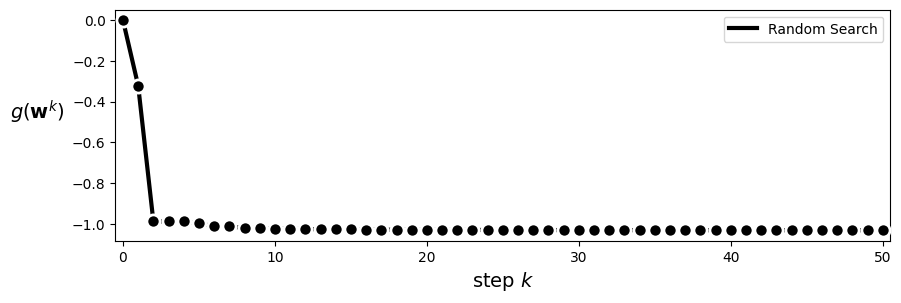

In [20]:
# first run with alpha = 1
alpha_choice = "diminishing"; w = np.array([0, 0]); num_samples = 1000; max_its = 50
weight_history, cost_history = random_search(g,alpha_choice,max_its,w,num_samples)

# plot the cost function history
static_plotter.plot_cost_histories([cost_history],start=0,points=True,labels=[r'Random Search'])

In [21]:
# the argmin found
last_weights = weight_history[-1]
last_weights

array([-0.09957931,  0.7138414 ])

We converged to one of the global minimum (−0.0898, 0.7126) starting from (0, 0).

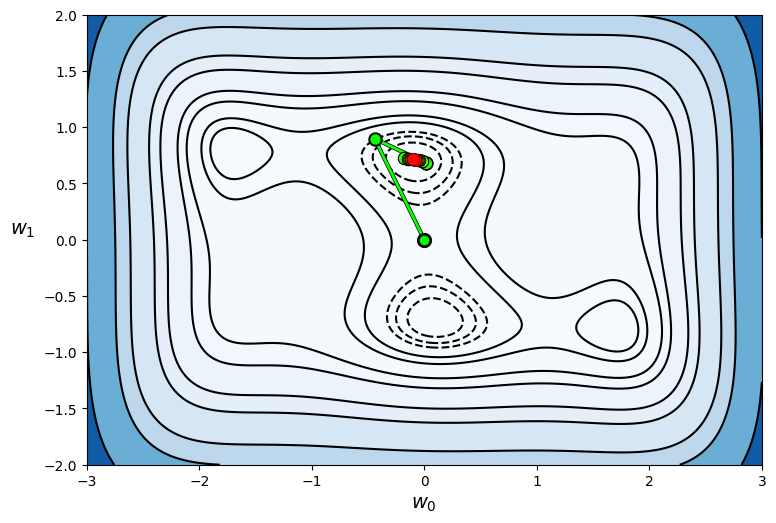

In [22]:
# contour plot of the function g with overlayed w_history to visualize the search path
static_plotter.two_input_contour_plot(g,weight_history,xmin = -3,xmax= 3,ymin = -2,ymax = 2,num_contours = 30,show_original = False)

The countour plot confirmed the above assertion.